In [1]:
%load_ext autoreload
%autoreload 2
import sys 
sys.path.append('../')
import os
import torch
import torch.distributions as dist
import torch.nn as nn
from typing import List
from tqdm import tqdm
from torch.utils.tensorboard import SummaryWriter
from utils import load_mnist_dataset, flatten_image, unflatten_image, view_image
from unet import get_timestep_embedding, UNet
from simple_bridge import SimpleBrownianBridgeDiffusion
from ddpm import DiffusionModel
from collections import OrderedDict

import matplotlib.pyplot as plt
import numpy as np

from torchmetrics.image.fid import FrechetInceptionDistance

In [2]:
def view_images(images, n_steps):
    """
    Function to view a sequence of images in one column.
    :param images: List of images
    :param n_steps: List of steps corresponding to each image
    :return: None
    """
    n = len(images)
    fig, axes = plt.subplots(n, 1, figsize=(5, 5 * n))
    
    if n == 1:
        axes = [axes]
    
    for i, (image, step) in enumerate(zip(images, n_steps)):
        ax = axes[i]
        ax.imshow(image.squeeze(), cmap='gray')
        ax.set_title(f'Step: {step}')
        ax.axis('off')
    
    plt.tight_layout()
    plt.show()

def view_images_two_models(images1, images2, n_steps):
    """
    Function to view a sequence of images from two models in two columns.
    :param images1: List of images from the first model
    :param images2: List of images from the second model
    :param n_steps: List of steps corresponding to each image
    :return: None
    """
    n = len(images1)
    fig, axes = plt.subplots(n, 2, figsize=(10, 5 * n))
    
    for i, step in enumerate(n_steps):
        ax1, ax2 = axes[i]
        
        ax1.imshow(images1[i].squeeze(), cmap='gray')
        ax1.set_title(f'Model 1 - Step: {step}')
        ax1.axis('off')
        
        ax2.imshow(images2[i].squeeze(), cmap='gray')
        ax2.set_title(f'Model 2 - Step: {step}')
        ax2.axis('off')
    
    plt.tight_layout()
    plt.show()

def view_images_multiple_models(images_list, n_steps, model_names):
    """
    Function to view a sequence of images from multiple models in columns.
    :param images_list: List of lists of images from each model
    :param n_steps: List of steps corresponding to each image
    :param model_names: List of model names
    :return: None
    """
    n = len(n_steps)
    num_models = len(images_list)
    fig, axes = plt.subplots(n, num_models, figsize=(5 * num_models, 5 * n))
    
    for i, step in enumerate(n_steps):
        for j in range(num_models):
            ax = axes[i, j] if num_models > 1 else axes[i]
            ax.imshow(images_list[j][i].squeeze(), cmap='gray')
            ax.set_title(f'{model_names[j]} - Step: {step}')
            ax.axis('off')
    
    plt.tight_layout()
    plt.show()

In [3]:
trainY, testY = load_mnist_dataset(root='/workspace/aim-bridges-data/mnist', download=False)

In [4]:
def remove_module_prefix(state_dict):
    """Remove 'module.' prefix from state_dict keys.
    it gets added when using DataParallel"""
    new_state_dict = OrderedDict()
    for k, v in state_dict.items():
        if k.startswith('module.'):
            new_state_dict[k[7:]] = v  # Remove 'module.' prefix
        else:
            new_state_dict[k] = v
    return new_state_dict

In [6]:
model = UNet()
checkpoint_path = '/workspace/aim-bridges-models/bridge/checkpoints/batch_128_T_0.1_stoch_checkpoint_n_batch_40000.pth'
print(f"Loading checkpoint '{checkpoint_path}'")
checkpoint = torch.load(checkpoint_path)
model.load_state_dict(remove_module_prefix(checkpoint))

Loading checkpoint '/workspace/aim-bridges-models/bridge/checkpoints/batch_128_T_0.1_stoch_checkpoint_n_batch_40000.pth'


FileNotFoundError: [Errno 2] No such file or directory: '/workspace/aim-bridges-models/bridge/checkpoints/batch_128_T_0.1_stoch_checkpoint_n_batch_40000.pth'

In [134]:
# Use DataParallel to wrap the model for multi-GPU training
#if torch.cuda.device_count() > 1:
#    print(f"Using {torch.cuda.device_count()} GPUs for sampling")
#    model = nn.DataParallel(model)

  0%|          | 0/100 [00:00<?, ?it/s]/workspace/generative-bridges/jupyter/../simple_bridge.py:77: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  t = torch.tensor(t, device=self.device)
100%|██████████| 100/100 [00:01<00:00, 63.10it/s]


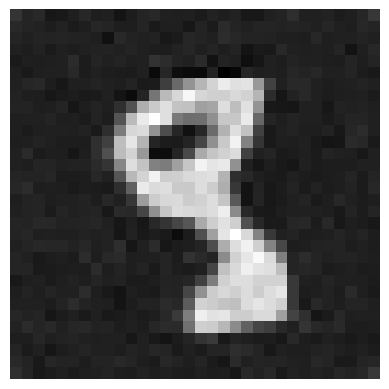

In [157]:
T = 0.1
diffusion_model = SimpleBrownianBridgeDiffusion(T, model, 'cuda', trainY, deterministic=False)
samples = diffusion_model.sampling(n_samples=1, use_tqdm=True, n_steps=100)
view_image(samples.cpu()[0])

In [7]:
model_denoise = UNet()
checkpoint_path = '/workspace/aim-bridges-models/denoise/checkpoints/batch_128_t_steps_1000_stoch_checkpoint_n_batch_500.pth'
print(f"Loading checkpoint '{checkpoint_path}'")
checkpoint = torch.load(checkpoint_path)
model_denoise.load_state_dict(remove_module_prefix(checkpoint))

Loading checkpoint '/workspace/aim-bridges-models/denoise/checkpoints/batch_128_t_steps_1000_stoch_checkpoint_n_batch_500.pth'


FileNotFoundError: [Errno 2] No such file or directory: '/workspace/aim-bridges-models/denoise/checkpoints/batch_128_t_steps_1000_stoch_checkpoint_n_batch_500.pth'

100%|██████████| 100/100 [00:01<00:00, 59.14it/s]


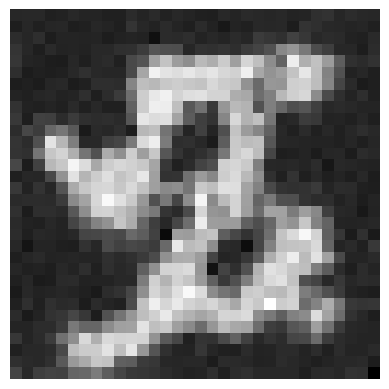

In [159]:
T = 100
diffusion_model_denoise = DiffusionModel(T, model_denoise, 'cuda', trainY)
samples = diffusion_model_denoise.sampling(n_samples=1, use_tqdm=True)
view_image(samples.cpu()[0])

In [ ]:
# Generate and visualize samples at different steps for both models
n_samples = 1
n_steps_list = [100, 200, 300, 400, 500, 600, 700, 800, 900, 1000]

# Samples for the first model
samples_model1 = []
for n_steps in n_steps_list:
    sample = diffusion_model.sampling(n_samples=n_samples, use_tqdm=False, n_steps=n_steps)
    samples_model1.append(sample.cpu()[0])

# Samples for the second model
samples_model2 = []
for n_steps in n_steps_list:
    diffusion_model_denoise = DiffusionModel(n_steps, model_denoise, 'cuda', trainY)
    sample = diffusion_model_denoise.sampling(n_samples=n_samples, use_tqdm=False)
    samples_model2.append(sample.cpu()[0])

# Visualize the samples
view_images_two_models(samples_model1, samples_model2, n_steps_list)

In [90]:
# bridge models
model = UNet()
checkpoint_path = '/workspace/aim-bridges-models/bridge/checkpoints/batch_128_T_0.1_stoch_checkpoint_n_batch_500.pth'
print(f"Loading checkpoint '{checkpoint_path}'")
checkpoint = torch.load(checkpoint_path)
model.load_state_dict(remove_module_prefix(checkpoint))

T = 0.1
bridge_500 = SimpleBrownianBridgeDiffusion(T, model, 'cuda', trainY, deterministic=False)

model = UNet()
checkpoint_path = '/workspace/aim-bridges-models/bridge/checkpoints/batch_128_T_0.1_stoch_checkpoint_n_batch_2000.pth'
print(f"Loading checkpoint '{checkpoint_path}'")
checkpoint = torch.load(checkpoint_path)
model.load_state_dict(remove_module_prefix(checkpoint))

T = 0.1
bridge_2000 = SimpleBrownianBridgeDiffusion(T, model, 'cuda', trainY, deterministic=False)

model = UNet()
checkpoint_path = '/workspace/aim-bridges-models/bridge/checkpoints/batch_128_T_0.1_stoch_checkpoint_n_batch_8000.pth'
print(f"Loading checkpoint '{checkpoint_path}'")
checkpoint = torch.load(checkpoint_path)
model.load_state_dict(remove_module_prefix(checkpoint))

T = 0.1
bridge_8000 = SimpleBrownianBridgeDiffusion(T, model, 'cuda', trainY, deterministic=False)

# denoising models
denoise_500 = UNet()
checkpoint_path = '/workspace/aim-bridges-models/denoise/checkpoints/batch_128_t_steps_1000_stoch_checkpoint_n_batch_500.pth'
print(f"Loading checkpoint '{checkpoint_path}'")
checkpoint = torch.load(checkpoint_path)
denoise_500.load_state_dict(remove_module_prefix(checkpoint))

denoise_2000 = UNet()
checkpoint_path = '/workspace/aim-bridges-models/denoise/checkpoints/batch_128_t_steps_1000_stoch_checkpoint_n_batch_2000.pth'
print(f"Loading checkpoint '{checkpoint_path}'")
checkpoint = torch.load(checkpoint_path)
denoise_2000.load_state_dict(remove_module_prefix(checkpoint))

denoise_8000 = UNet()
checkpoint_path = '/workspace/aim-bridges-models/denoise/checkpoints/batch_128_t_steps_1000_stoch_checkpoint_n_batch_8000.pth'
print(f"Loading checkpoint '{checkpoint_path}'")
checkpoint = torch.load(checkpoint_path)
denoise_8000.load_state_dict(remove_module_prefix(checkpoint))

Loading checkpoint '/workspace/aim-bridges-models/bridge/checkpoints/batch_128_T_0.1_stoch_checkpoint_n_batch_500.pth'
Loading checkpoint '/workspace/aim-bridges-models/bridge/checkpoints/batch_128_T_0.1_stoch_checkpoint_n_batch_2000.pth'
Loading checkpoint '/workspace/aim-bridges-models/bridge/checkpoints/batch_128_T_0.1_stoch_checkpoint_n_batch_8000.pth'
Loading checkpoint '/workspace/aim-bridges-models/denoise/checkpoints/batch_128_t_steps_1000_stoch_checkpoint_n_batch_500.pth'
Loading checkpoint '/workspace/aim-bridges-models/denoise/checkpoints/batch_128_t_steps_1000_stoch_checkpoint_n_batch_2000.pth'
Loading checkpoint '/workspace/aim-bridges-models/denoise/checkpoints/batch_128_t_steps_1000_stoch_checkpoint_n_batch_8000.pth'


<All keys matched successfully>

/workspace/generative-bridges/jupyter/../simple_bridge.py:77: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  t = torch.tensor(t, device=self.device)


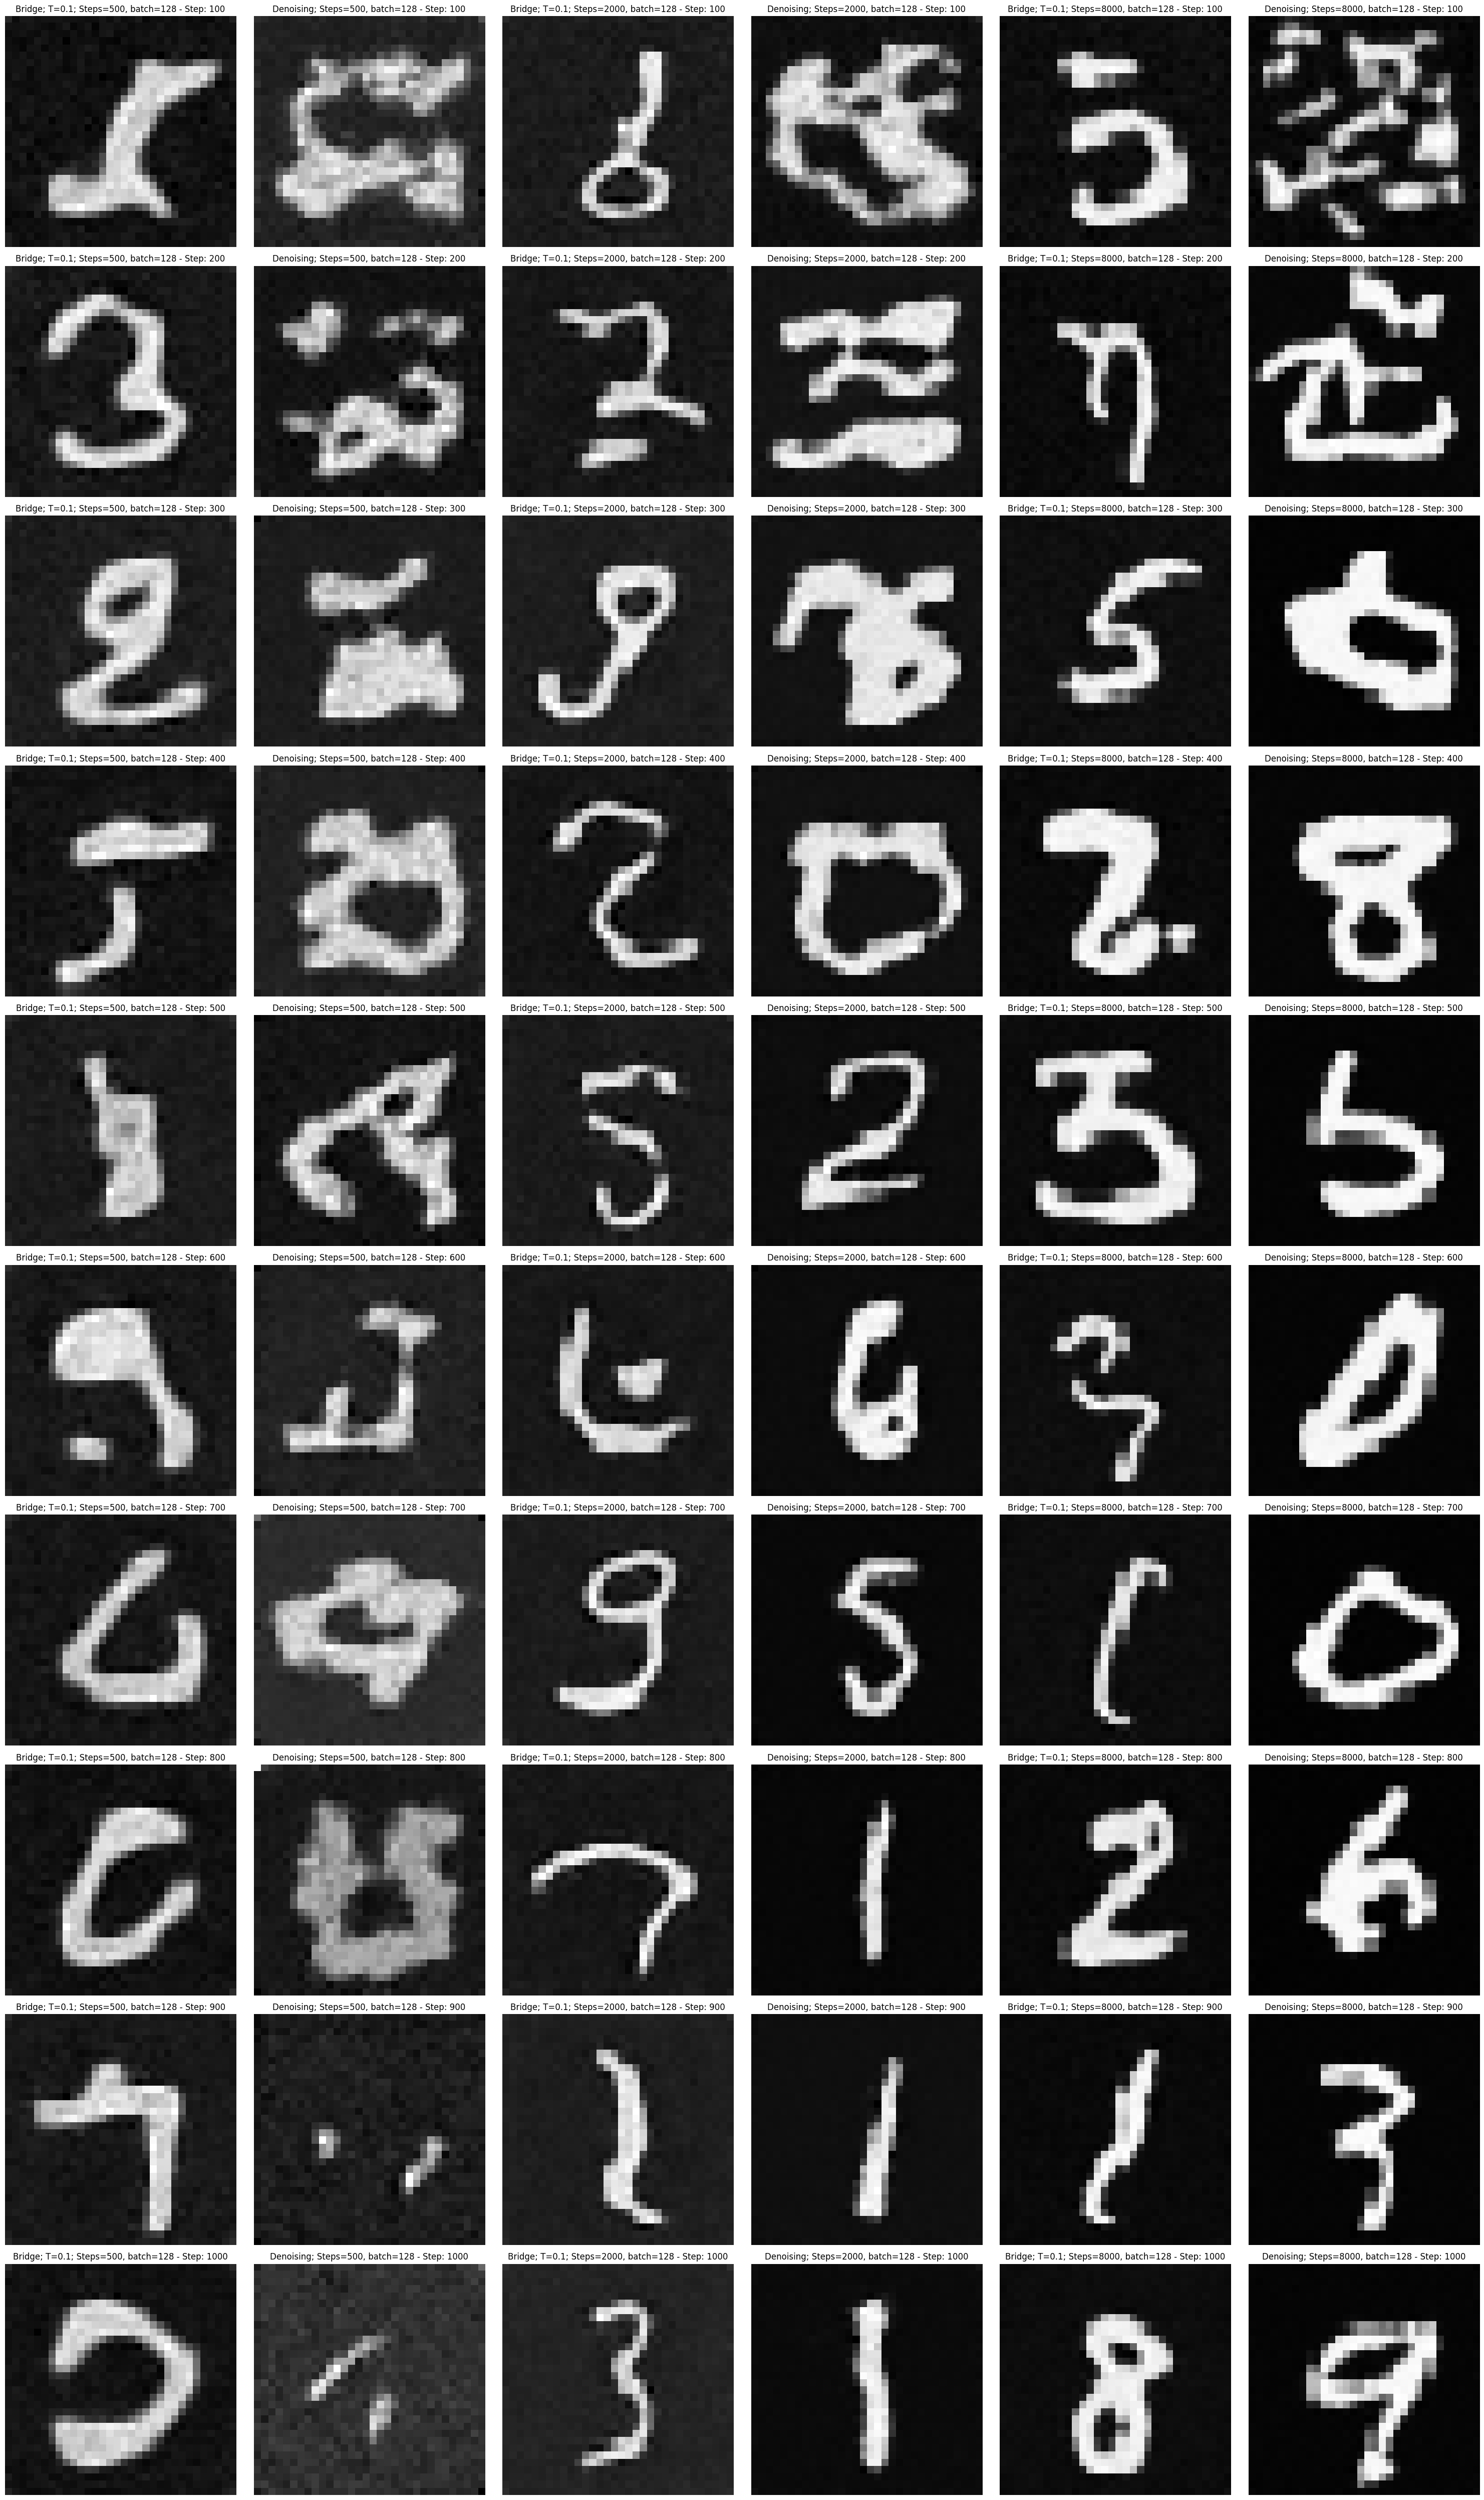

In [164]:
# Generate and visualize samples at different steps for multiple models
n_samples = 1
n_steps_list = [100, 200, 300, 400, 500, 600, 700, 800, 900, 1000]
model_names = ['Bridge; T=0.1; Steps=500, batch=128', 'Denoising; Steps=500, batch=128', 'Bridge; T=0.1; Steps=2000, batch=128', 'Denoising; Steps=2000, batch=128', 'Bridge; T=0.1; Steps=8000, batch=128', 'Denoising; Steps=8000, batch=128']
# List of models
models = [bridge_500, denoise_500, bridge_2000, denoise_2000, bridge_8000, denoise_8000 ]

# Function to generate samples for a given model
def generate_samples(_model, n_samples, n_steps_list, name):
    samples = []
    for n_steps in n_steps_list:
        if 'Denoising' in name:
            _model_denoise = DiffusionModel(n_steps, _model, 'cuda', trainY)
            sample = _model_denoise.sampling(n_samples=n_samples, use_tqdm=False)
        else:
            sample = _model.sampling(n_samples=n_samples, use_tqdm=False, n_steps=n_steps)
        samples.append(sample.cpu()[0])
    return samples

# Generate samples for all models
samples_list = [generate_samples(model, n_samples, n_steps_list, name) for model, name in zip(models, model_names)]

# Visualize the samples
view_images_multiple_models(samples_list, n_steps_list, model_names)

In [2]:
fid = FrechetInceptionDistance(feature=64)

Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to /workspace/.cache/torch/hub/checkpoints/weights-inception-2015-12-05-6726825d.pth
100%|██████████| 91.2M/91.2M [00:01<00:00, 56.4MB/s]


In [4]:
imgs_dist1 = torch.randint(0, 200, (100, 3, 299, 299), dtype=torch.uint8)
imgs_dist1.shape

torch.Size([100, 3, 299, 299])

In [5]:
imgs_dist2 = torch.randint(100, 255, (100, 3, 299, 299), dtype=torch.uint8)

In [6]:
fid.update(imgs_dist1, real=True)

In [7]:
fid.update(imgs_dist2, real=False)

In [8]:
fid.compute()

tensor(12.7171)

In [12]:
testY[0].shape

torch.Size([784])

In [16]:

def unflatten_data(vector, shape=(28, 28)):
    """
    Function to unflatten an image
    :param vector: Flattened image tensor
    :param shape: Target shape
    :return: Unflattened image tensor
    """
    return vector.view(-1, 1, *shape)

def sample_batch(trainY, batch_size, device):
    indices = torch.randperm(len(trainY))[:batch_size]
    data = torch.stack([trainY[i] for i in indices]).to(device)
    data = unflatten_data(data)  # Reshape to (batch_size, 1, 28, 28)
    return torch.nn.functional.interpolate(data, size=(32, 32))

In [86]:
train_sample = sample_batch(trainY=trainY, batch_size=100, device='cuda')
test_sample = sample_batch(trainY=testY, batch_size=100, device='cuda')

In [49]:
def process_image(image):
    image = (image - image.min()) / (image.max() - image.min())  # Normalize to [0, 1]
    image = (image * 255).clamp(0, 255).byte()  # Scale to [0, 255] and convert to uint8
    image = image.repeat(3, 1, 1) 
    return image

In [64]:
train_sample_int  = torch.stack([process_image(samp) for samp in train_sample])
test_sample_int = torch.stack([process_image(samp) for samp in test_sample])

In [51]:
fid = FrechetInceptionDistance(feature=64)
fid.update(train_sample_int, real=True)
fid.update(test_sample_int, real=False)

In [52]:
fid.compute()

tensor(0.0072)

In [102]:
samples_bridge_500 = bridge_500.sampling(n_samples=100, use_tqdm=False, n_steps=1000)
samples_bridge_500_int = torch.stack([process_image(samp) for samp in samples_bridge_500])

samples_bridge_2000 = bridge_2000 .sampling(n_samples=100, use_tqdm=False, n_steps=1000)
samples_bridge_2000_int = torch.stack([process_image(samp) for samp in samples_bridge_2000])

samples_bridge_8000 = bridge_8000.sampling(n_samples=100, use_tqdm=False, n_steps=1000)
samples_bridge_8000_int = torch.stack([process_image(samp) for samp in samples_bridge_8000])

/workspace/generative-bridges/jupyter/../simple_bridge.py:77: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  t = torch.tensor(t, device=self.device)


In [103]:
model_denoise_500 = DiffusionModel(1000, denoise_500, 'cuda', trainY)
sample_denoise_500 = model_denoise_500.sampling(n_samples=100, use_tqdm=False)
sample_denoise_500_int = torch.stack([process_image(samp) for samp in sample_denoise_500])

model_denoise_8000 = DiffusionModel(1000, denoise_8000, 'cuda', trainY)
sample_denoise_8000 = model_denoise_8000.sampling(n_samples=100, use_tqdm=False)
sample_denoise_8000_int = torch.stack([process_image(samp) for samp in sample_denoise_8000])

In [105]:
fid = FrechetInceptionDistance(feature=64).to('cuda')
fid.update(test_sample_int, real=True)
fid.update(samples_bridge_500_int, real=False)
fid.compute()

tensor(5.1161, device='cuda:0')

In [106]:
fid = FrechetInceptionDistance(feature=64).to('cuda')
fid.update(test_sample_int, real=True)
fid.update(samples_bridge_2000_int, real=False)
fid.compute()

tensor(2.4652, device='cuda:0')

In [107]:
fid = FrechetInceptionDistance(feature=64).to('cuda')
fid.update(test_sample_int, real=True)
fid.update(samples_bridge_8000_int, real=False)
fid.compute()

tensor(0.8542, device='cuda:0')

In [108]:
fid = FrechetInceptionDistance(feature=64).to('cuda')
fid.update(test_sample_int, real=True)
fid.update(sample_denoise_500_int, real=False)
fid.compute()

tensor(7.5607, device='cuda:0')

In [109]:
fid = FrechetInceptionDistance(feature=64).to('cuda')
fid.update(test_sample_int, real=True)
fid.update(sample_denoise_8000_int, real=False)
fid.compute()

tensor(0.3196, device='cuda:0')

In [94]:
n_samples = 100
n_steps_list = [100]#, 200, 300, 400, 500, 600, 700, 800, 900, 1000]
model_names = ['Bridge; T=0.1; Steps=500, batch=128', 'Denoising; Steps=500, batch=128', 'Bridge; T=0.1; Steps=2000, batch=128', 'Denoising; Steps=2000, batch=128', 'Bridge; T=0.1; Steps=8000, batch=128', 'Denoising; Steps=8000, batch=128']
# List of models
models = [bridge_500, denoise_500, bridge_2000, denoise_2000, bridge_8000, denoise_8000 ]
# Function to generate samples for a given model
def generate_samples(_model, n_samples, n_steps_list, name):
    samples = []
    for n_steps in n_steps_list:
        if 'Denoising' in name:
            _model_denoise = DiffusionModel(n_steps, _model, 'cuda', trainY)
            sample = _model_denoise.sampling(n_samples=n_samples, use_tqdm=False)
        else:
            sample = _model.sampling(n_samples=n_samples, use_tqdm=False, n_steps=n_steps)
        samples.append(sample)
    return samples

# Initialize lists to store FID scores
fid_scores = []

# Loop over models and their names
for model, name in zip(models[0:1], model_names[0:1]):
    model_samples = generate_samples(model, n_samples=n_samples, n_steps_list=n_steps_list, name=name)
    for n_steps in n_steps_list:
        model_samples_int = torch.stack([process_image(samp) for samp in model_samples])
        fid = FrechetInceptionDistance(feature=64).to('cuda')
        fid.update(test_sample_int, real=True)
        fid.update(model_samples_int, real=False)
        fid_scores.append(fid.compute())

/workspace/generative-bridges/jupyter/../simple_bridge.py:77: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  t = torch.tensor(t, device=self.device)


RuntimeError: Number of dimensions of repeat dims can not be smaller than number of dimensions of tensor

In [96]:
model_samples_int.shape

torch.Size([1, 3, 32, 32])

In [83]:
fid_scores

[]

In [ ]:
# Plotting the FID scores
plt.figure(figsize=(10, 8))

for fid_value, name in zip(fid_scores, model_names):
    if 'Denoising' in name:
        plt.plot(n_steps_list, fid_value, linestyle='dotted', label=name)
    else:
        plt.plot(n_steps_list, fid_value, linestyle='solid', label=name)

plt.xlabel('Number of Steps')
plt.ylabel('FID Score')
plt.title('FID Scores by Model and Time Steps')
plt.legend()
plt.grid(True)
plt.show()

In [4]:


import cv2

im = cv2.imread('/workspace/aim-bridges-img/sample_9.png')

In [5]:
im.shape

(32, 32, 3)